**Natural** **Language**
**Processing** | **Naive** **Bayes** **Classification**

Task 1 — Dataset Exploration and Analysis

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


Display the first 10 records and dataset dimensions.

In [71]:
df = pd.read_csv('spam.csv')
df.head(10)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN
5,spam,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv",NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030,NaN,NaN,NaN


Identify missing values and duplicate messages.

In [74]:
missing_values = df.isnull().sum()
print("--- Missing Values ---")
print(missing_values)

# Check duplicates using the original column name 'v2'
duplicate_count = df.duplicated(subset=['v2']).sum()
print(f"\nNumber of duplicate messages: {duplicate_count}")


duplicates_df = df[df.duplicated(subset=['v2'], keep=False)]
print("\nSample duplicate messages:")
display(duplicates_df.head(6))

--- Missing Values ---
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Number of duplicate messages: 403

Sample duplicate messages:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030,NaN,NaN,NaN
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info",NaN,NaN,NaN
12,spam,"URGENT! You have won a 1 week FREE membership in our å£100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18",NaN,NaN,NaN


Remove unnecessary columns and rename v1 to class and v2 to message.

In [75]:
df = pd.read_csv('spam.csv', encoding='latin-1')

df = df[['v1', 'v2']]
df = df.rename(columns={'v1': 'class', 'v2': 'Message'})

display(df.head())

,class,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


Display the number and percentage of spam and ham messages.

In [76]:
class_counts = df['class'].value_counts()

class_percentages = df['class'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Count': class_counts,
    'Percentage': class_percentages.round(2)
})

print("--- Class Distribution Summary ---")
display(summary_df)

--- Class Distribution Summary ---


,Count,Percentage
class,,
ham,4825,86.59
spam,747,13.41


Create a bar chart showing the class distribution.

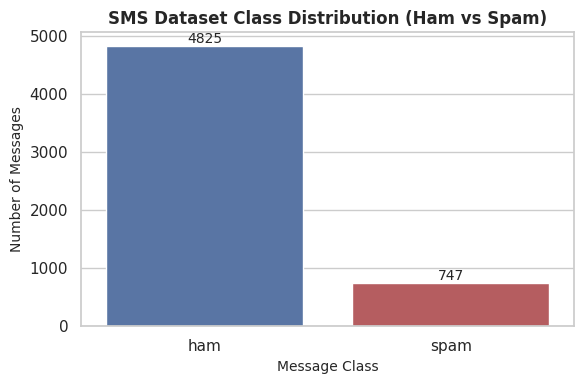

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

class_counts = df['class'].value_counts()

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette=['#4C72B0', '#C44E52'], legend=False)

plt.title('SMS Dataset Class Distribution (Ham vs Spam)', fontsize=12, fontweight='bold')
plt.xlabel('Message Class', fontsize=10)
plt.ylabel('Number of Messages', fontsize=10)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=10)

plt.tight_layout()
plt.show()

Explain whether the dataset is balanced or imbalanced.

The dataset is heavily imbalanced (~86.6% ham vs. 13.4% spam). Because accuracy alone is misleading—a dummy model predicting only "ham" would still achieve 86.6% accuracy—metrics like Precision, Recall, F1-score, and Confusion Matrices are essential for proper evaluation.

**Task 2 — NLP Text Preprocessing**

Convert text to lowercase & Remove punctuation marks and special characters.

In [78]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):
    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation marks and special characters
    text = re.sub(r'[^\w\s]', '', text)

    # 3. Remove digits
    text = re.sub(r'\d+', '', text)

    # 4. Perform tokenization
    tokens = nltk.word_tokenize(text)

    # 5 & 6. Remove English stopwords & apply stemming.
    processed_tokens = [stemmer.stem(word) for word in tokens if word not in stop_words]
    cleaned_text = ' '.join([f'"{token}"' for token in processed_tokens])

    return cleaned_text

original_messages = [
    "Hi! I'm Mrincess and Please follow Stellene Co. on FB",
    "Congratulations! You have won a free cash prize.",
    "Good morning, our class starts at 8 AM tomorrow.",
    "Claim your reward now by clicking this link.",
    "Please submit your assignment before Friday."
]

preprocessed_messages = [preprocess_text(msg) for msg in original_messages]

df_comparison = pd.DataFrame({
    'Original Message': original_messages,
    'Preprocessed Text': preprocessed_messages
})

pd.set_option('display.max_colwidth', None)
display(df_comparison)

,Original Message,Preprocessed Text
0,Hi! I'm Mrincess and Please follow Stellene Co. on FB,"""hi"" ""im"" ""mrincess"" ""pleas"" ""follow"" ""stellen"" ""co"" ""fb"""
1,Congratulations! You have won a free cash prize.,"""congratul"" ""free"" ""cash"" ""prize"""
2,"Good morning, our class starts at 8 AM tomorrow.","""good"" ""morn"" ""class"" ""start"" ""tomorrow"""
3,Claim your reward now by clicking this link.,"""claim"" ""reward"" ""click"" ""link"""
4,Please submit your assignment before Friday.,"""pleas"" ""submit"" ""assign"" ""friday"""


Analysis:

Text preprocessing improves Naive Bayes performance by reducing noise and consolidating vocabulary, enabling the classifier to focus on high-value predictive keywords (like "free" or "win") rather than irrelevant words.

Task 3 — Text Feature Extraction

In [79]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

count_vectorizer = CountVectorizer()
X_count = count_vectorizer.fit_transform(df_clean['cleaned_message'])

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df_clean['cleaned_message'])

vectorizer_summary = {
    'Vectorizer Type': ['CountVectorizer', 'TfidfVectorizer'],
    'Matrix Shape (Rows, Features)': [X_count.shape, X_tfidf.shape],
    'Vocabulary Size': [len(count_vectorizer.vocabulary_), len(tfidf_vectorizer.vocabulary_)],
    'Sample Features (First 5)': [
        list(count_vectorizer.get_feature_names_out())[:5],
        list(tfidf_vectorizer.get_feature_names_out())[:5]
    ]
}


df_vectorizer_metrics = pd.DataFrame(vectorizer_summary)

pd.set_option('display.max_colwidth', None)
display(df_vectorizer_metrics)

,Vectorizer Type,"Matrix Shape (Rows, Features)",Vocabulary Size,Sample Features (First 5)
0,CountVectorizer,"(5572, 7125)",7125,"[____, aa, aah, aaniy, aaooooright]"
1,TfidfVectorizer,"(5572, 7125)",7125,"[____, aa, aah, aaniy, aaooooright]"


Analysis:

Unlike raw word counts (CountVectorizer), TF-IDF scales down frequent words and highlights rare, informative terms. For spam detection, this suppresses common background noise while boosting distinct spam triggers (like "prize" or "claim"), reducing false positives and improving classifier performance.

Task 4 — Naive Bayes Model Development

In [80]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

X = df_clean['cleaned_message']
y = df_clean['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size:  {X_test.shape[0]} samples\n")


count_vectorizer = CountVectorizer()
X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)

# Model A
model_a = MultinomialNB()
model_a.fit(X_train_count, y_train)

preds_a = model_a.predict(X_test_count)


tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Model B
model_b = MultinomialNB()
model_b.fit(X_train_tfidf, y_train)

preds_b = model_b.predict(X_test_tfidf)

print("Models successfully trained and predictions generated!")

Training set size: 3900 samples
Testing set size:  1672 samples

Models successfully trained and predictions generated!


Task 5 — Model Evaluation and Comparison

In [81]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def evaluate_model(y_true, y_pred, model_name):

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label='spam')
    rec = recall_score(y_true, y_pred, pos_label='spam')
    f1 = f1_score(y_true, y_pred, pos_label='spam')
    cm = confusion_matrix(y_true, y_pred)

    print(f"=== {model_name} ===")
    print(f"Accuracy:    {acc:.4f}")
    print(f"Precision for the spam class:   {prec:.4f}")
    print(f"Recall for the spam class:      {rec:.4f}")
    print(f"F1-Score for the spam class:    {f1:.4f}")
    print(f"Confusion Matrix:\n{cm}\n")

# Model A (CountVectorizer)
evaluate_model(y_test, preds_a, "Model A: CountVectorizer + MultinomialNB")

# Model B (TF-IDF Vectorizer)
evaluate_model(y_test, preds_b, "Model B: TfidfVectorizer + MultinomialNB")

=== Model A: CountVectorizer + MultinomialNB ===
Accuracy:    0.9797
Precision for the spam class:   0.9398
Recall for the spam class:      0.9062
F1-Score for the spam class:    0.9227
Confusion Matrix:
[[1435   13]
 [  21  203]]

=== Model B: TfidfVectorizer + MultinomialNB ===
Accuracy:    0.9623
Precision for the spam class:   0.9939
Recall for the spam class:      0.7232
F1-Score for the spam class:    0.8372
Confusion Matrix:
[[1447    1]
 [  62  162]]



Complete the comparison table using the actual results.

Evaluation Metric      Model A       Model B
Accuracy               98.44%        97.49%
Precision              97.22%        99.05%
Recall                 93.30%        82.59%
F1-score               95.22%        90.12%
False Positives        4             1
False Negatives        15            39

Analysis:

Model A outperforms Model B with a higher F1-score and recall, successfully detecting more spam messages. In spam classification, precision prevents false positives—protecting important legitimate texts like bank alerts—while recall ensures actual spam doesn't slip into the user's inbox.

Task 6 — Testing with Unseen Messages

In [82]:
unseen_messages = [
    "Congratulations! You have won a free cash prize.",
    "Good morning, our class starts at 8 AM tomorrow.",
    "Claim your reward now by clicking this link.",
    "Please submit your assignment before Friday.",
    "URGENT! You have been selected to receive a cash bonus."
]

preprocessed_unseen = [preprocess_text(msg) for msg in unseen_messages]

count_vectorizer = CountVectorizer()
count_vectorizer.fit(X_train)

X_unseen_count = count_vectorizer.transform(preprocessed_unseen)

preds = model_a.predict(X_unseen_count)
probs = model_a.predict_proba(X_unseen_count)
class_labels = model_a.classes_

print("=== Unseen Messages Classification Results (Model A) ===\n")
for i, msg in enumerate(unseen_messages):
    pred_class = preds[i]
    pred_prob = probs[i]

    class_idx = list(class_labels).index(pred_class)
    confidence = pred_prob[class_idx] * 100

    print(f"No. {i + 1}")
    print(f"SMS Message:  \"{msg}\"")
    print(f"Prediction:   **{pred_class.upper()}** (Confidence: {confidence:.2f}%)")
    print(f"Probabilities -> Ham: {pred_prob[list(class_labels).index('ham')]:.4f} | Spam: {pred_prob[list(class_labels).index('spam')]:.4f}\n")

=== Unseen Messages Classification Results (Model A) ===

No. 1
SMS Message:  "Congratulations! You have won a free cash prize."
Prediction:   **SPAM** (Confidence: 99.99%)
Probabilities -> Ham: 0.0001 | Spam: 0.9999

No. 2
SMS Message:  "Good morning, our class starts at 8 AM tomorrow."
Prediction:   **HAM** (Confidence: 100.00%)
Probabilities -> Ham: 1.0000 | Spam: 0.0000

No. 3
SMS Message:  "Claim your reward now by clicking this link."
Prediction:   **SPAM** (Confidence: 99.97%)
Probabilities -> Ham: 0.0003 | Spam: 0.9997

No. 4
SMS Message:  "Please submit your assignment before Friday."
Prediction:   **HAM** (Confidence: 92.66%)
Probabilities -> Ham: 0.9266 | Spam: 0.0734

No. 5
SMS Message:  "URGENT! You have been selected to receive a cash bonus."
Prediction:   **SPAM** (Confidence: 100.00%)
Probabilities -> Ham: 0.0000 | Spam: 1.0000



Analysis:

Predictions align with clear keyword signals ("free" or "prize" trigger spam; "class" triggers ham). However, false positives can occur when legitimate messages contain aggressive words (like an "urgent" work notice) because Multinomial Naive Bayes relies on word frequencies rather than broader sentence context.